# 3_analise.ipynb — Camada Gold, perguntas de negócio e gráficos

**Projeto:** Viagens a Serviço (Portal da Transparência)
**Fluxo de camadas:** Raw → Silver → **Gold**


---

### O que este notebook faz?

Este notebook representa a **Fase 3** do pipeline ETL. Ele parte das tabelas **Silver** — já limpas e tipadas pelo script `2_transformar.py` — e dá dois passos:

1. **Constrói a camada Gold**, com tabelas e *views* agregadas que resumem os dados para análise.
2. **Responde as 7 perguntas de negócio** propostas no projeto.

Toda pergunta segue o mesmo roteiro, o que mantém a análise padronizada e fácil de acompanhar:


- Pergunta  →  Consulta SQL  →  Tabela  →  Gráfico  →  Conclusão


---


### Regra de análise adotada

Todas as perguntas consideram **apenas viagens efetivamente realizadas**, ou seja, registros com:

```sql
situacao = 'Realizada'
```

**Por quê?**
Viagens canceladas, não iniciadas ou ainda em aberto **não representam gasto nem deslocamento real**. Incluí-las distorceria médias, somas e rankings. Filtrar por `'Realizada'` garante que os números reflitam apenas o que de fato aconteceu.

---

### Onde cada pergunta é respondida

As perguntas estão divididas conforme a camada usada para respondê-las: algumas saem direto da **Silver**, outras exigem agregações da **Gold** (com `JOIN` e `GROUP BY`).

| Camada | Tipo de consulta | Perguntas |
|---|---|---|
| **Silver** | Consulta direta | 1. Órgãos com maior custo <br> 2. Destinos com maior custo médio <br> 3. Viagem de maior duração |
| **Gold** | Tabela e view com `JOIN` + `GROUP BY` | 4. Tipo de pagamento com maior valor médio <br> 5. Meio de transporte mais usado <br> 6. UF de destino mais frequente <br> 7. Órgão que mais pagou |



### Antes de executar

Para que este notebook funcione corretamente, **execute os scripts na ordem**:

1. `0_criar_banco.sql` — cria o banco e as tabelas das camadas Raw e Silver;
2. `1_extrair.py` — baixa os CSVs e carrega a camada Raw;
3. `2_transformar.py` — limpa, tipa e carrega a camada Silver.

Além disso, confira se o arquivo **`.env`** está preenchido com a sua senha do PostgreSQL.

⚠️ Sem esses pré-requisitos atendidos, o notebook não conseguirá ler a Silver e, portanto, não conseguirá gerar a Gold nem responder às perguntas.

---

### Preparação: bibliotecas e conexão

Antes de qualquer consulta ou gráfico, o notebook precisa preparar três coisas: **as bibliotecas**, **a conexão com o banco** e **as funções auxiliares** que vão ser usadas em todas as etapas seguintes.



#### Bibliotecas utilizadas

| Biblioteca | Para que serve neste notebook |
|---|---|
| `pandas` | Organiza o resultado das consultas SQL em tabelas (DataFrames). |
| `matplotlib` | Desenha os gráficos a partir dessas tabelas. |
| `banco.conectar()` | Abre a conexão com o banco `transparencia`, usando a senha definida no arquivo `.env`. |

**Por que usar `banco.conectar()`?**

Toda a configuração do PostgreSQL (host, porta, usuário, senha e nome do banco) fica centralizada no `.env`. Assim, o notebook não precisa repetir credenciais — basta reaproveitar a função já criada no módulo `banco.py`.

In [1]:
# teste de conexão com o banco de dados
import warnings
warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

import matplotlib.pyplot as plt
import pandas as pd

from banco import conectar


# mostra os números das tabelas com 2 casas decimais
pd.set_option("display.float_format", "{:.2f}".format)


def consultar(sql):
    conexao = conectar()
    tabela = pd.read_sql(sql, conexao)
    conexao.close()
    return tabela


def executar(sql):
    """Executa comandos SQL sem retorno (CREATE, DROP, INSERT...)."""
    conexao = conectar()              # abre a conexão
    conexao.autocommit = True         # confirma cada comando automaticamente
    cursor = conexao.cursor()         # cria o cursor
    try:
        cursor.execute(sql)           # executa o SQL
    finally:
        cursor.close()                # fecha o cursor
        conexao.close()               # fecha a conexão


def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


teste = consultar("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. Viagens na camada Silver:", teste["viagens"][0])

Conexão OK. Viagens na camada Silver: 341860


---
# Respondendo as peguntas de negócio:

## 1. Quais são os 5 órgãos com maior custo total?

Os 5 órgãos com maior custo total são:


,orgao,custo_total,custo_milhoes
0,Ministério da Justiça e Segurança Pública,485748241.43,485.75
1,Ministério da Defesa,154595910.29,154.60
2,Ministério da Educação,109759836.03,109.76
3,Ministério do Meio Ambiente e Mudança do Clima,49300595.26,49.30
4,Ministério da Previdência Social,40236180.79,40.24


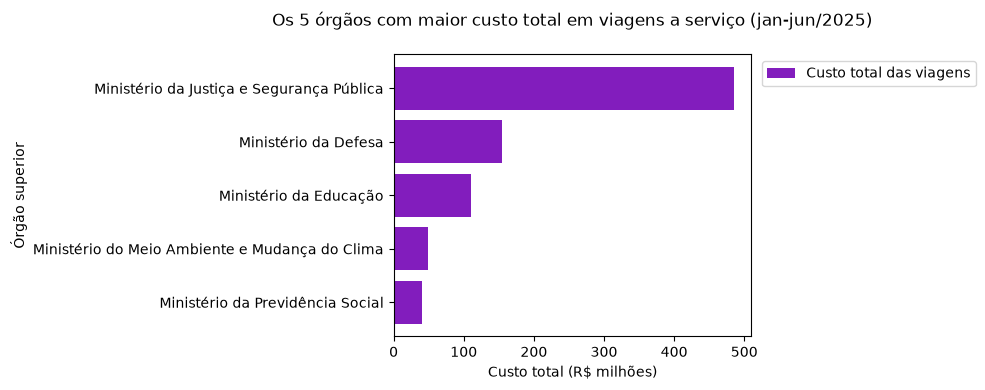

É possível identificar uma diferença significativa de R$ 331.15 milhões de reais entre o primeiro e segundo colocados da lista de órgãos.


In [28]:
# Busca os 5 órgãos com maior custo total, considerando só viagens realizadas
sql_top_orgaos = """
    SELECT nome_orgao_superior AS orgao,     
           SUM(valor_total)    AS custo_total -- soma o custo de todas as viagens do órgão
    FROM silver_viagem
    WHERE situacao = 'Realizada'             -- ignora viagens canceladas/não realizadas
    GROUP BY nome_orgao_superior             -- agrupa por órgão
    ORDER BY custo_total DESC                -- ordena do maior para o menor
    LIMIT 5                                  -- só os 5 primeiros
"""

# Executa a consulta e devolve como tabela do Pandas
tabela = consultar(sql_top_orgaos)

# Cria uma coluna extra em milhões, para o gráfico ficar mais legível
tabela["custo_milhoes"] = tabela["custo_total"] / 1_000_000

# Mostra a tabela formatada na tela
print(f"Os 5 órgãos com maior custo total são:")
display(tabela)


# Gráfico de barras horizontais
# Cria a figura e o eixo, com tamanho confortável para leitura
fig, ax = plt.subplots(figsize=(10, 4))

# Desenha as barras: órgão no eixo Y, custo em milhões no eixo X
ax.barh(
    tabela["orgao"],
    tabela["custo_milhoes"],
    color="#821DBD",         
    label="Custo total das viagens",
)

# Inverte o eixo Y para o maior valor ficar no topo
ax.invert_yaxis()

# Define títulos dos eixos e do gráfico
ax.set_title("Os 5 órgãos com maior custo total em viagens a serviço (jan-jun/2025)\n")
ax.set_xlabel("Custo total (R$ milhões)")
ax.set_ylabel("Órgão superior")

# Coloca a legenda fora do gráfico, para não cobrir as barras
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

# Ajusta o layout para não cortar nada e exibe o gráfico
plt.tight_layout()
plt.show()


# Diferença entre o primeiro e o segundo colocado da lista
dif = tabela["custo_total"].iloc[0] - tabela["custo_total"].iloc[1]
print(f"É possível identificar uma diferença significativa de R$ {(dif / 1_000_000):.2f} milhões de reais entre o primeiro e segundo colocados da lista de órgãos.")

## 2. Os 3 destinos com maior custo médio por viagem?

In [4]:
# ===========================================================================
# Pergunta 2: quais destinos finais têm o maior custo médio por viagem?
# Estratégia: criar uma VIEW no PostgreSQL que já devolve o destino final
# (última cidade do roteiro) e reutilizá-la em qualquer consulta futura.
# ===========================================================================


# ---------------------------------------------------------------------------
# Passo 1 — Cria (ou substitui) a view com a coluna destino_final
# ---------------------------------------------------------------------------

# SQL que cria a view no banco. Se ela já existir, é substituída.
# A ideia: pegar tudo o que vem DEPOIS da última vírgula da coluna destinos.

# TRIM - Remove espaços em branco do começo e do fim do texto.
# SPLIT_PART(texto, separador, posição) 

sql_criar_view = """
    CREATE OR REPLACE VIEW vw_viagem_destino_final AS
    SELECT
        id_viagem,
        situacao,
        valor_total,
        TRIM(SPLIT_PART(destinos, ',', -1)) AS destino_final -- quebra a coluna "destinos" separando por "," e pega a última posição
    FROM silver_viagem;
"""

# Executa a criação da view direto no banco
executar(sql_criar_view)

print("View vw_viagem_destino_final criada (ou atualizada).")


View vw_viagem_destino_final criada (ou atualizada).


In [ ]:
# ---------------------------------------------------------------------------
# Passo 2 — Consulta a view, já com o destino final pronto
# ---------------------------------------------------------------------------

# Filtra viagens realizadas e traz o que interessa.
sql_destinos = """
    SELECT destino_final,
           valor_total
    FROM vw_viagem_destino_final
    WHERE situacao = 'Realizada'
"""

# Executa a consulta — já vem com a coluna destino_final separada
tabela = consultar(sql_destinos)

# Mostra uma amostra para conferir se a separação ficou correta
display(tabela.head())

,destino_final,valor_total
0,Nova Delhi/Índia,13306.83
1,Rio de Janeiro/RJ,9773.24
2,Moscou/Rússia,7570.98
3,Rio de Janeiro/RJ,4281.84
4,Rio de Janeiro/RJ,2356.31


In [10]:
# ---------------------------------------------------------------------------
# Passo 3 — Agrupa por destino final e calcula viagens + custo médio
# ---------------------------------------------------------------------------

# Agrupa pela coluna destino_final, conta viagens e calcula a média do custo
resumo = (
    tabela
    .groupby("destino_final")
    .agg(
        viagens=("valor_total", "count"),       # quantas viagens terminaram nesse destino
        custo_medio=("valor_total", "mean"),    # média do custo por viagem
    )
    .reset_index()
)

# Arredonda o custo médio para 2 casas decimais
resumo["custo_medio"] = resumo["custo_medio"].round(2)

# Mostra quantos destinos finais únicos existem antes do filtro
print(f"Destinos finais únicos encontrados: {len(resumo)}")

Destinos finais únicos encontrados: 5318


In [11]:
# ---------------------------------------------------------------------------
# Passo 4 — Filtra destinos finais com 100 viagens ou mais
# ---------------------------------------------------------------------------

# Só entram destinos finais com pelo menos 100 viagens
resumo = resumo[resumo["viagens"] >= 100]

# Ordena do maior custo médio para o menor e pega os 3 primeiros
top3 = resumo.sort_values("custo_medio", ascending=False).head(3).reset_index(drop=True)

# Mostra o resultado final
display(top3)

,destino_final,viagens,custo_medio
0,Tucumã/PA,118,29092.23
1,Guaíra/PR,129,27402.57
2,Genebra/Suíça,254,25530.77


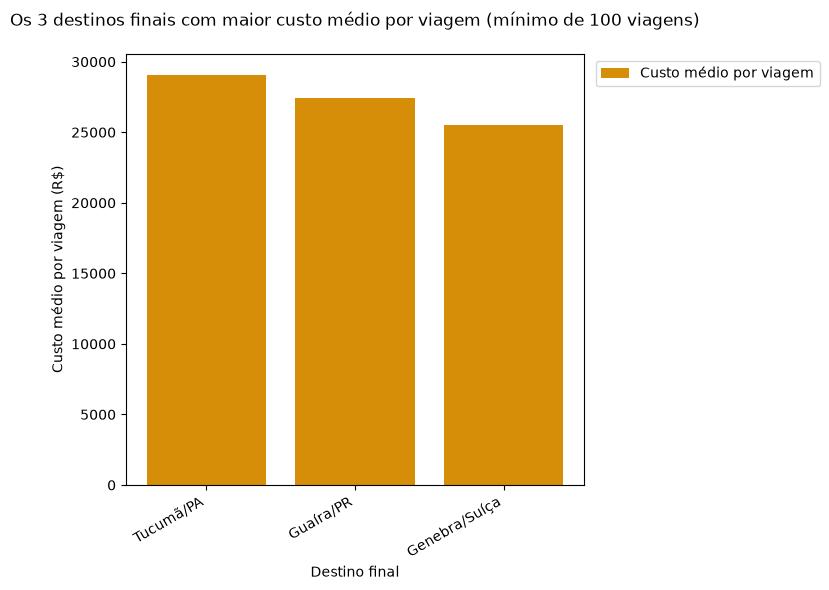

Conclusão: 
Tucumã/PA é o destino final com o maior custo médio por viagem: R$ 29.092,23, em 118 viagens. 
Aqui só entram destinos finais com 100 viagens ou mais, para a média não ficar destorcida.


In [30]:

# ---------------------------------------------------------------------------
# Passo 5 — Gráfico de barras verticais
# ---------------------------------------------------------------------------

# Cria a figura e o eixo, com proporção mais alta para caber os nomes embaixo
fig, ax = plt.subplots(figsize=(8, 6))

# Desenha as barras: destino final no eixo X, custo médio no eixo Y
ax.bar(
    top3["destino_final"],
    top3["custo_medio"],
    color="#D68E08",                    
    label="Custo médio por viagem",
)

# Títulos do gráfico e dos eixos
ax.set_title("Os 3 destinos finais com maior custo médio por viagem (mínimo de 100 viagens)\n")
ax.set_xlabel("Destino final")
ax.set_ylabel("Custo médio por viagem (R$)")

# Gira os rótulos do eixo X em 30º, para nomes longos não se sobreporem
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# Legenda fora do gráfico, para não cobrir as barras
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

# Ajusta o layout e exibe
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# Passo 6 — Conclusão em texto
# ---------------------------------------------------------------------------

# Pega o primeiro colocado do ranking
lider = top3.iloc[0]

# Imprime a conclusão com o nome do destino final já extraído pela view
print(
    f"Conclusão: \n{lider['destino_final']} é o destino final com o maior custo médio por viagem: R$ {formatar_numero(lider['custo_medio'])}, "
    f"em {lider['viagens']} viagens. "
    f"\nAqui só entram destinos finais com 100 viagens ou mais, para a média não ficar destorcida."
)